# Why deep networks train at all

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/1_foundations/03_depth_and_residuals.ipynb) &nbsp; Guide note: [guide-foundations](https://www.matthewwnuk.com/guide-foundations.html#depth)

Stacking plain layers stops working quickly. This notebook measures why, by looking at the gradient
that reaches each layer, and then shows the two ingredients that fix it: residual connections and
normalisation.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
X, y = data.digits(); X, y = torch.tensor(X), torch.tensor(y)
idx = torch.randperm(len(y), generator=torch.Generator().manual_seed(0)); tr, va = idx[:1300], idx[1300:]

class Residual(nn.Module):
    """x + f(norm(x)): the block every transformer is built from."""
    def __init__(self, h): super().__init__(); self.norm = nn.LayerNorm(h); self.lin = nn.Linear(h, h)
    def forward(self, x): return x + self.lin(F.relu(self.norm(x)))

def build(depth, kind, h=64):
    body = [m for _ in range(depth) for m in ((nn.Linear(h, h), nn.ReLU()) if kind == "plain" else (Residual(h),))]
    return nn.Sequential(nn.Linear(64, h), *body, nn.Linear(h, 10))

## The gradient that reaches each layer

Build a 32-layer network, compute the loss on one batch, and look at the size of the gradient at every
layer before any training has happened.

plain     first layer 3.5e-13   last layer 3.2e-02   ratio 9.1e+10
residual  first layer 4.0e+00   last layer 6.4e+00   ratio 1.6e+00


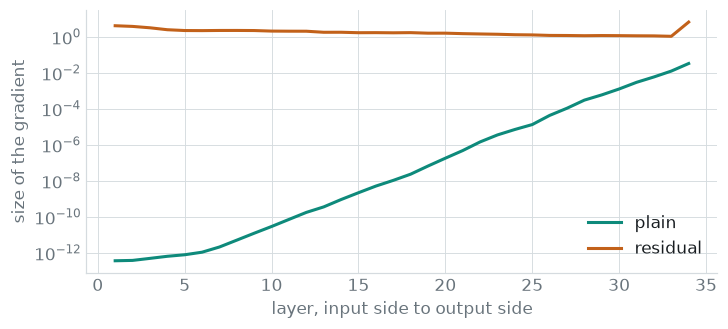

In [3]:
plt.figure(figsize=(7.4, 3.1))
for kind in ("plain", "residual"):
    torch.manual_seed(0); m = build(32, kind); F.cross_entropy(m(X[tr[:256]]), y[tr[:256]]).backward()
    norms = [p.grad.norm().item() for n, p in m.named_parameters() if p.ndim == 2]
    plt.plot(range(1, len(norms) + 1), norms, label=kind); print(f"{kind:9s} first layer {norms[0]:.1e}   last layer {norms[-1]:.1e}   ratio {norms[-1] / norms[0]:.1e}")
plt.yscale("log"); plt.xlabel("layer, input side to output side"); plt.ylabel("size of the gradient"); plt.legend(); plt.show()

In the plain network the gradient shrinks at every layer on the way back, so the early layers receive
almost nothing and never learn. With residual connections each layer adds a correction to its input,
the derivative contains an identity term, and the gradient passes straight through.

## What that does to training

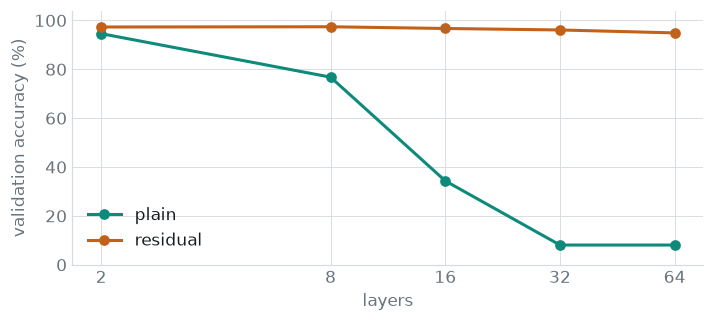

plain ['95%', '77%', '34%', '8%', '8%']
residual ['97%', '97%', '97%', '96%', '95%']


In [4]:
def accuracy(depth, kind, seed=0, epochs=12):
    torch.manual_seed(seed); m = build(depth, kind); opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epochs):
        perm = tr[torch.randperm(len(tr))]
        for i in range(0, len(perm), 64):
            b = perm[i:i + 64]; loss = F.cross_entropy(m(X[b]), y[b]); opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad(): return (m(X[va]).argmax(1) == y[va]).float().mean().item()

depths = [2, 8, 16, 32, 64]; res = {k: [np.mean([accuracy(d, k, s) for s in range(2)]) for d in depths] for k in ("plain", "residual")}
plt.figure(figsize=(7.4, 3))
for k, v in res.items(): plt.plot(depths, np.array(v) * 100, marker="o", label=k)
plt.xscale("log", base=2); plt.xticks(depths, depths); plt.ylim(0, 104); plt.xlabel("layers"); plt.ylabel("validation accuracy (%)"); plt.legend(); plt.show()
for k, v in res.items(): print(k, [f"{a:.0%}" for a in v])

## Things to try

- Remove the `LayerNorm` from `Residual` and repeat. Which of the two ingredients matters more here?
- Give the plain network a careful initialisation (`nn.init.kaiming_normal_`) and see how far that alone gets.
- Plot the size of the activations, not the gradients, layer by layer.